# Tome S1, Chapter 9: Symmetry Diagonalises (Python companion)

Exercises first, solutions at the end. We let the FFT diagonalise circulants, find characters by simultaneous diagonalisation, compute Gauss sums and the spectra and clique numbers of Paley graphs, check the Krawtchouk tables of the Hamming cube, solve Delsarte's linear program for small codes, and factor group determinants, abelian and not. We use `numpy`, `scipy`, `sympy`, `networkx`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, time
from math import comb
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import sympy as sp
import scipy.linalg
from scipy.optimize import linprog
rng = np.random.default_rng(9)

## Exercises

**P9.1 (★) Circulants by FFT.** For a random circulant of size $n=8$, compare `numpy.linalg.eigvals` with the values $p(\omega^a)$ of Theorem 9.1, computed with one FFT. Then solve $Cx=b$ for $n=2^{12}$ by FFT and by Gaussian elimination, and compare the times and the answers.

**P9.2 (★) Which integers are $a^3+b^3+c^3-3abc$?** List the integers $|N|\le60$ of this form with $|a|,|b|,|c|\le25$ and compare with the rule of Exercise 9.2.

**P9.3 (★★) Characters from linear algebra.** For $G=\Z/4\times\Z/2$, build the eight translation matrices, diagonalise a random linear combination of them (Lemma 9.6), and check that each eigenvector, scaled to have value $1$ at $0$, is a character (Theorem 9.7). Print the character table.

**P9.4 (★★) Paley graphs.** For the primes $p\equiv1\pmod4$ below $100$, compute the Gauss sum $g(1)$, the spectrum of $P_p$ (Theorem 9.9) and its clique number, and compare the clique number with $\sqrt p$ and with $\log_2p$. Check that $P_{17}$ has no $K_4$ and no independent set of size $4$ (Exercise 9.10).

**P9.5 (★) Krawtchouk tables.** For $n=6$, build the distance matrices $D_k$ of the cube, check that $D_k\chi_T=K_k(|T|)\chi_T$ and the orthogonality relation of Theorem 9.11, and plot the Krawtchouk polynomials for $n=10$.

**P9.6 (★★) Delsarte's linear program.** Solve the linear program of Corollary 9.13 for $n\le14$ and $d=4$ and compare with the best known values $A(n,4)=4,8,16,20,40,72,144,256,512$ for $n=6,\dots,14$, with the Plotkin bound when it applies, and with the greedy (lexicographic) codes. Then check the hand proof of Exercise 9.12.

**P9.7 (★) Group determinants.** Factor the group determinant of $\Z/4$, of $(\Z/2)^2$ and of the symmetric group $S_3$ (Theorem 9.16). What is different for $S_3$?

## Solutions

### P9.1
**How to find it.** With the convention $C_{jk}=c_{k-j}$, the eigenvalue on $v_a$ is $p(\omega^a)=\sum_kc_k\omega^{ak}$, which is $n$ times the inverse FFT of $c$. To solve $Cx=b$, diagonalise: $C=F\Lambda F^*$, so $x=F\Lambda^{-1}F^*b$, two FFTs and a division.

In [2]:
def circulant(c):
    n = len(c)
    return np.array([[c[(k - j) % n] for k in range(n)] for j in range(n)])

n = 8; c = rng.standard_normal(n); Cm = circulant(c)
lam = n * np.fft.ifft(c)                     # p(omega^a), a = 0..n-1
ev = np.linalg.eigvals(Cm)
print("eigenvalues match:", np.allclose(np.sort_complex(ev), np.sort_complex(lam)))
print("det:", np.linalg.det(Cm), " product of p(omega^a):", np.prod(lam).real)

n = 2 ** 11; c = rng.standard_normal(n); c[0] += 2 * np.abs(c).sum()   # keep it well conditioned
b = rng.standard_normal(n)
Cbig = scipy.linalg.circulant(c).T          # scipy's convention is the transpose of ours
t0 = time.perf_counter()
lam = n * np.fft.ifft(c)                     # eigenvalues p(omega^a)
x_fft = np.fft.ifft(np.fft.fft(b) / lam).real
t_fft = time.perf_counter() - t0
t0 = time.perf_counter(); x_ge = np.linalg.solve(Cbig, b); t_ge = time.perf_counter() - t0
print(f"n = {n}: FFT {t_fft*1e3:.2f} ms, Gaussian elimination {t_ge*1e3:.0f} ms,"
      f" max difference {np.abs(x_fft - x_ge).max():.1e}")

eigenvalues match: True
det: 67.0435115646252  product of p(omega^a): 67.04351156462523


n = 2048: FFT 0.75 ms, Gaussian elimination 78 ms, max difference 2.5e-18


Check of the conventions: $x=\sum_a\frac{\langle b,v_a\rangle}{n\,p(\omega^a)}v_a$, and $\langle b,v_a\rangle=\sum_jb_j\omega^{-aj}$ is exactly `np.fft.fft(b)[a]`, while $\frac1n\sum_a y_a\omega^{aj}$ is `np.fft.ifft(y)[j]`. The FFT route costs $O(n\log n)$ against $O(n^3)$, and the gap is already large at this size.

### P9.2
**How to find it.** Brute force over a box. Since $N=(a+b+c)Q$ with $Q\ge0$, small $N$ are reached with small $a,b,c$.

In [3]:
B = 25
vals = set()
r = np.arange(-B, B + 1)
a, b, c = np.meshgrid(r, r, r, indexing="ij")
N = a**3 + b**3 + c**3 - 3 * a * b * c
vals = set(int(v) for v in N[np.abs(N) <= 60].ravel())
predicted = {m for m in range(-60, 61) if m % 9 not in (3, 6)}
print("found == predicted:", vals == predicted)
print("missing integers in [-60, 60]:", sorted(set(range(-60, 61)) - vals))

found == predicted: True
missing integers in [-60, 60]: [-60, -57, -51, -48, -42, -39, -33, -30, -24, -21, -15, -12, -6, -3, 3, 6, 12, 15, 21, 24, 30, 33, 39, 42, 48, 51, 57, 60]


Exactly the integers $\equiv\pm3\pmod9$ are missing: $\pm3,\pm6,\pm12,\pm15,\dots$.

### P9.3
**How to find it.** A random combination of commuting diagonalisable matrices has, with probability one, distinct eigenvalues on distinct common eigenspaces, so its eigenvectors are the common eigenvectors.

In [4]:
G = [(x, y) for x in range(4) for y in range(2)]
idx = {g: i for i, g in enumerate(G)}
add = lambda g, h: ((g[0] + h[0]) % 4, (g[1] + h[1]) % 2)
def T(g):   # (T_g f)(x) = f(x + g)
    M = np.zeros((8, 8))
    for x in G: M[idx[x], idx[add(x, g)]] = 1
    return M
Ts = [T(g) for g in G]
print("translations commute:", all(np.allclose(A @ B, B @ A) for A in Ts for B in Ts))
M = sum(complex(*rng.standard_normal(2)) * A for A in Ts)
w, V = np.linalg.eig(M)
chars = [V[:, j] / V[idx[(0, 0)], j] for j in range(8)]
is_char = all(np.isclose(chi[idx[add(g, h)]], chi[idx[g]] * chi[idx[h]]) for chi in chars for g in G for h in G)
print("all eigenvectors are characters:", is_char)
tab = np.array(chars)
print("orthogonality: chi chi^* = 8 I:", np.allclose(tab @ tab.conj().T, 8 * np.eye(8)))
print("character table (rows: characters, columns:", G, ")")
for chi in sorted(chars, key=lambda v: (round(np.angle(v[idx[(1, 0)]]), 3), round(v[idx[(0, 1)]].real))):
    print("  ", " ".join(f"{z.real:+.0f}" if abs(z.imag) < 1e-9 else f"{z.imag:+.0f}i" for z in chi))

translations commute: True
all eigenvectors are characters: True
orthogonality: chi chi^* = 8 I: True
character table (rows: characters, columns: [(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1)] )
   +1 -1 -1 +1 +1 -1 -1 +1
   +1 -1 -1i +1i -1 +1 +1i -1i
   +1 +1 -1i -1i -1 -1 +1i +1i
   +1 -1 +1 -1 +1 -1 +1 -1
   +1 +1 +1 +1 +1 +1 +1 +1
   +1 -1 +1i -1i -1 +1 -1i +1i
   +1 +1 +1i +1i -1 -1 -1i -1i
   +1 +1 -1 -1 +1 +1 -1 -1


Each character is determined by $\chi(1,0)\in\{1,i,-1,-i\}$ and $\chi(0,1)\in\{1,-1\}$: the table is the product of the tables of $\Z/4$ and $\Z/2$ (Exercise 9.4).

### P9.4
**How to find it.** `networkx` finds maximum cliques exactly for graphs of this size. The independence number is the clique number of the complement, which is isomorphic to the graph itself.

In [5]:
def paley(p):
    S = {x * x % p for x in range(1, p)}
    G = nx.Graph(); G.add_nodes_from(range(p))
    G.add_edges_from((x, y) for x in range(p) for y in range(x + 1, p) if (y - x) % p in S)
    return G

print(" p   g(1)      sqrt p   eigenvalues (rounded)          clique  sqrt p  log2 p")
for p in [q for q in range(5, 100) if sp.isprime(q) and q % 4 == 1]:
    g1 = sum(np.exp(2j * np.pi * x * x / p) for x in range(p))
    G = paley(p); A = nx.to_numpy_array(G)
    ev = np.round(np.linalg.eigvalsh(A), 4)
    vals, counts = np.unique(ev, return_counts=True)
    spec = ", ".join(f"{v:g}^{m}" for v, m in zip(vals[::-1], counts[::-1]))
    omega = max(len(c) for c in nx.find_cliques(G))
    print(f"{p:3d} {g1.real:+8.4f}  {math.sqrt(p):7.4f}   {spec:30s} {omega:4d}  {math.sqrt(p):6.2f}  {math.log2(p):6.2f}")

G17 = paley(17)
print("P17: max clique", max(len(c) for c in nx.find_cliques(G17)),
      " max independent set", max(len(c) for c in nx.find_cliques(nx.complement(G17))))

 p   g(1)      sqrt p   eigenvalues (rounded)          clique  sqrt p  log2 p
  5  +2.2361   2.2361   2^1, 0.618^2, -1.618^2            2    2.24    2.32
 13  +3.6056   3.6056   6^1, 1.3028^6, -2.3028^6          3    3.61    3.70
 17  +4.1231   4.1231   8^1, 1.5616^8, -2.5616^8          3    4.12    4.09
 29  +5.3852   5.3852   14^1, 2.1926^14, -3.1926^14       4    5.39    4.86
 37  +6.0828   6.0828   18^1, 2.5414^18, -3.5414^18       4    6.08    5.21
 41  +6.4031   6.4031   20^1, 2.7016^20, -3.7016^20       5    6.40    5.36
 53  +7.2801   7.2801   26^1, 3.1401^26, -4.1401^26       5    7.28    5.73
 61  +7.8102   7.8102   30^1, 3.4051^30, -4.4051^30       5    7.81    5.93
 73  +8.5440   8.5440   36^1, 3.772^36, -4.772^36         5    8.54    6.19
 89  +9.4340   9.4340   44^1, 4.217^44, -5.217^44         5    9.43    6.48


 97  +9.8489   9.8489   48^1, 4.4244^48, -5.4244^48       6    9.85    6.60
P17: max clique 3  max independent set 3


The Gauss sum is always $+\sqrt p$ (Gauss's theorem), the spectrum is $\frac{p-1}2$ once and $\frac{-1\pm\sqrt p}2$ each $\frac{p-1}2$ times, and the clique number stays far below $\sqrt p$, close to $\log_2p$: the Hoffman bound is honest but weak here, and nobody knows how to prove anything like $\log p$. The graph $P_{17}$ is the extremal colouring for $R(4,4)=18$.

### P9.5
**How to find it.** Index words by integers $0..2^n-1$; the Hamming distance is the popcount of the XOR; $\chi_T(x)=(-1)^{|x\wedge T|}$.

D_k chi_T = K_k(|T|) chi_T for all k, T: True
orthogonality matrix / 2^n: [ 1  6 15 20 15  6  1]  off-diagonal all zero: True


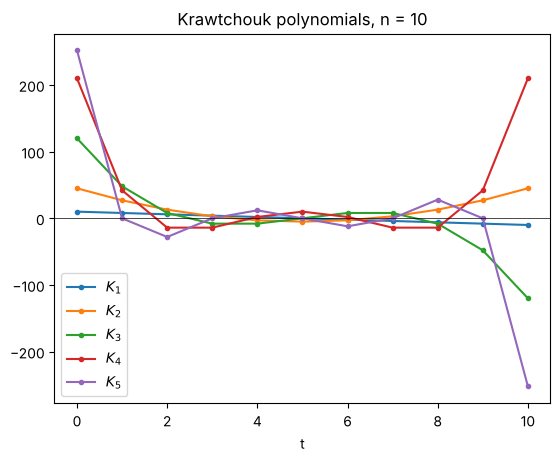

In [6]:
def K(n, k, t):
    return sum((-1) ** j * comb(t, j) * comb(n - t, k - j) for j in range(k + 1))

n = 6; N = 2 ** n
pc = lambda v: bin(v).count("1")
X = np.arange(N)
dist = np.array([[pc(x ^ y) for y in X] for x in X])
H = np.array([[(-1) ** pc(x & T) for T in X] for x in X])     # columns are the characters chi_T
ok = True
for k in range(n + 1):
    Dk = (dist == k).astype(int)
    ok &= np.array_equal(Dk @ H, H * np.array([K(n, k, pc(T)) for T in X]))
print("D_k chi_T = K_k(|T|) chi_T for all k, T:", ok)
Gram = np.array([[sum(comb(n, t) * K(n, k, t) * K(n, l, t) for t in range(n + 1)) for l in range(n + 1)] for k in range(n + 1)])
print("orthogonality matrix / 2^n:", np.diag(Gram) // N, " off-diagonal all zero:", np.count_nonzero(Gram - np.diag(np.diag(Gram))) == 0)

n = 10; ts = np.arange(n + 1)
for k in range(1, 6):
    plt.plot(ts, [K(n, k, t) for t in ts], marker="o", ms=3, label=f"$K_{k}$")
plt.axhline(0, color="k", lw=0.5); plt.legend(); plt.title("Krawtchouk polynomials, n = 10"); plt.xlabel("t"); plt.show()

The diagonal of the orthogonality matrix is $\binom6k$, as predicted. The plot shows the polynomials oscillating with $k$ sign changes, like their continuous cousins the Hermite polynomials (which they approach after rescaling).

### P9.6
**How to find it.** `scipy.optimize.linprog` minimises, so we minimise $-\sum a_i$ subject to $-\sum_i a_iK_k(i)\le\binom nk$. The lexicographic code scans the words in order and keeps each one at distance at least $d$ from all kept words.

In [7]:
def lp_bound(n, d, ks=None):
    I = list(range(d, n + 1)); ks = list(ks or range(1, n + 1))
    A_ub = [[-K(n, k, i) for i in I] for k in ks]; b_ub = [comb(n, k) for k in ks]
    res = linprog(-np.ones(len(I)), A_ub=A_ub, b_ub=b_ub, bounds=[(0, None)] * len(I), method="highs")
    return 1 - res.fun

def lexicode(n, d):
    code = []
    for w in range(2 ** n):
        if all(bin(w ^ c).count("1") >= d for c in code): code.append(w)
    return len(code)

known = {6: 4, 7: 8, 8: 16, 9: 20, 10: 40, 11: 72, 12: 144, 13: 256, 14: 512}
print(" n   LP bound   Plotkin   best known   lexicode")
for n in range(6, 15):
    pl = f"{8 / (8 - n):7.2f}" if 8 > n else "      -"
    print(f"{n:2d}  {lp_bound(n, 4):9.3f}   {pl}   {known[n]:6d}      {lexicode(n, 4):5d}")
print("A(8,4): LP with k = 1, 2 only:", lp_bound(8, 4, [1, 2]))

 n   LP bound   Plotkin   best known   lexicode
 6      4.000      4.00        4          4
 7      8.000      8.00        8          8
 8     16.000         -       16         16
 9     25.600         -       20         16
10     42.667         -       40         32
11     85.333         -       72         64
12    170.667         -      144        128
13    292.571         -      256        256


14    512.000         -      512        512
A(8,4): LP with k = 1, 2 only: 16.0


The LP bound is exact for $n\le8$, and then the gap opens: for $n=9$ the LP allows $25.6$ while the truth is $20$. Adding constraints (for instance that a code of even minimum distance can be assumed to have only even distances, or Schrijver's semidefinite refinement of 2005) closes part of the gap. The two inequalities $k=1,2$ already give $16$ for $n=8$, as in Exercise 9.12; the greedy lexicode reaches $16$ too, and it is a linear code equivalent to the extended Hamming code.

### P9.7
**How to find it.** Build the matrix $(x_{gh^{-1}})$; for speed, compute the determinant with the Berkowitz algorithm before factoring.

In [8]:
def group_det(elements, mul, inv):
    x = {g: sp.Symbol(f"x{i}") for i, g in enumerate(elements)}
    n = len(elements)
    M = sp.Matrix(n, n, lambda i, j: x[mul(elements[i], inv(elements[j]))])
    return sp.factor_list(sp.Poly(sp.expand(M.det(method="berkowitz"))))

Z4 = list(range(4))
print("Z/4:", group_det(Z4, lambda a, b: (a + b) % 4, lambda a: (-a) % 4))
V4 = [(a, b) for a in range(2) for b in range(2)]
print("(Z/2)^2:", group_det(V4, lambda g, h: ((g[0] + h[0]) % 2, (g[1] + h[1]) % 2), lambda g: g))
S3 = list(itertools.permutations(range(3)))
fl = group_det(S3, lambda a, b: tuple(a[b[i]] for i in range(3)), lambda a: tuple(sorted(range(3), key=lambda i: a[i])))
for f, e in fl[1]:
    print(f"S3 factor of degree {f.total_degree()} with multiplicity {e}: {f.as_expr()}")

Z/4: (1, [(Poly(x0 - x1 + x2 - x3, x0, x1, x2, x3, domain='ZZ'), 1), (Poly(x0 + x1 + x2 + x3, x0, x1, x2, x3, domain='ZZ'), 1), (Poly(x0**2 - 2*x0*x2 + x1**2 - 2*x1*x3 + x2**2 + x3**2, x0, x1, x2, x3, domain='ZZ'), 1)])
(Z/2)^2: (1, [(Poly(x0 - x1 - x2 + x3, x0, x1, x2, x3, domain='ZZ'), 1), (Poly(x0 - x1 + x2 - x3, x0, x1, x2, x3, domain='ZZ'), 1), (Poly(x0 + x1 - x2 - x3, x0, x1, x2, x3, domain='ZZ'), 1), (Poly(x0 + x1 + x2 + x3, x0, x1, x2, x3, domain='ZZ'), 1)])


S3 factor of degree 1 with multiplicity 1: x0 - x1 - x2 + x3 + x4 - x5
S3 factor of degree 1 with multiplicity 1: x0 + x1 + x2 + x3 + x4 + x5
S3 factor of degree 2 with multiplicity 2: x0**2 - x0*x3 - x0*x4 - x1**2 + x1*x2 + x1*x5 - x2**2 + x2*x5 + x3**2 - x3*x4 + x4**2 - x5**2


Over $\mathbb Q$, the group determinant of $\Z/4$ shows the factors $x_0+x_1+x_2+x_3$, $x_0-x_1+x_2-x_3$ and a quadratic: the two characters with values $\pm i$ are complex conjugate, and their linear factors multiply to a rational quadratic. For $(\Z/2)^2$ all four characters are real, and we get four linear factors. For $S_3$ there are two linear factors (the trivial character and the sign) and an irreducible quadratic factor appearing squared: the two-dimensional representation of $S_3$, of degree $2$ and multiplicity $2$, exactly as Frobenius found.